Almost every number a quant touches passes through NumPy. pandas stores its columns in NumPy arrays, scikit-learn takes NumPy arrays as input, PyTorch tensors convert to and from them for free, and Matplotlib plots them. If you understand NumPy well, every other library becomes easier, faster and less mysterious.

This chapter starts from nothing: you only need to know a Python list and a `for` loop. By the end you will vectorise a backtest, compute a portfolio's risk with one line of linear algebra, simulate ten thousand price paths in a fraction of a second, and know the traps (views, broadcasting, `ddof`, float precision) that silently corrupt results.

:::eli5
A Python list is a bag of things of any kind: a number, a word, another list. Python has to check each thing before it does anything with it, one by one. A NumPy array is a tray of identical boxes, each holding one number of the same type, packed side by side. Because every box is the same, the computer can process the whole tray in one go, in fast machine code. That is the entire trick, and it makes NumPy 10 to 100 times faster.
:::

## Setup

Every chapter starts with the same few lines. We fix the random seed so you get the same numbers as this page, and define a small helper that saves figures into the chapter's `images/` folder.

In [1]:
import sys
assert sys.version_info >= (3, 9)

import numpy as np
print("NumPy", np.__version__)

import matplotlib as mpl
import matplotlib.pyplot as plt
mpl.rc("axes", labelsize=12, titlesize=13)
mpl.rc("xtick", labelsize=10)
mpl.rc("ytick", labelsize=10)
mpl.rc("figure", dpi=110)

from pathlib import Path
IMAGES = Path("images")
IMAGES.mkdir(exist_ok=True)

def save_fig(name, tight=True):
    if tight:
        plt.tight_layout()
    plt.savefig(IMAGES / f"{name}.png", dpi=150, bbox_inches="tight")

R = {}                      # numbers quoted in the text of the guide
rng = np.random.default_rng(42)

NumPy 2.5.3


## Why NumPy? A speed test

Suppose you have a million daily prices and want the daily returns $r_t = P_t / P_{t-1} - 1$. First with a plain Python loop, then with NumPy.

In [2]:
import time

prices = list(100 * np.cumprod(1 + rng.normal(0, 0.01, 1_000_000)))

t0 = time.perf_counter()
returns_loop = []
for i in range(1, len(prices)):
    returns_loop.append(prices[i] / prices[i - 1] - 1)
t_loop = time.perf_counter() - t0

p = np.array(prices)
t0 = time.perf_counter()
returns_np = p[1:] / p[:-1] - 1
t_np = time.perf_counter() - t0

print(f"loop:  {t_loop*1000:7.1f} ms")
print(f"numpy: {t_np*1000:7.1f} ms   ({t_loop/t_np:.0f}x faster)")
print("same answer:", np.allclose(returns_loop, returns_np))
R["speedup"] = f"{t_loop/t_np:.0f}"

loop:    209.3 ms
numpy:     3.6 ms   (59x faster)
same answer: True


On this machine NumPy was about 59 times faster, and the code is shorter and closer to the maths. The line `p[1:] / p[:-1] - 1` reads as “every price from the second on, divided by every price up to the second-to-last, minus one”. No index variable, no off-by-one bookkeeping. This style is called **vectorisation**: you write the operation once for whole arrays and NumPy runs the loop for you in compiled C.

:::idea
Vectorised code is not only faster. It is closer to the formula, so it has fewer bugs. Throughout this course, a Python loop over the rows of data is a warning sign. There is almost always an array expression that does the same thing.
:::

## Creating arrays

An array has three properties that you should always know: its **shape** (how many elements along each axis), its **dtype** (the type of every element) and its number of dimensions, **ndim**.

In [3]:
a = np.array([1.5, 2.0, 3.25])          # from a Python list
print(a, a.shape, a.dtype, a.ndim)

M = np.array([[1, 2, 3],
              [4, 5, 6]])               # a list of lists -> 2-D
print(M)
print("shape", M.shape, "ndim", M.ndim, "size", M.size, "dtype", M.dtype)

[1.5  2.   3.25] (3,) float64 1
[[1 2 3]
 [4 5 6]]
shape (2, 3) ndim 2 size 6 dtype int64


Shape `(2, 3)` means 2 rows and 3 columns. The first number is always axis 0 (rows), the second axis 1 (columns). A 1-D array of three numbers has shape `(3,)`: the comma makes it a tuple with one entry.

You rarely type numbers in by hand. These constructors cover nearly every case:

In [4]:
print(np.zeros(4))                      # 4 zeros (float)
print(np.ones((2, 3), dtype=int))       # 2x3 of ones, as integers
print(np.full((2, 2), 0.05))            # every entry 0.05
print(np.arange(0, 10, 3))              # like range(): start, stop (excluded), step
print(np.linspace(0, 1, 5))             # 5 evenly spaced points, both ends included
print(np.eye(3))                        # identity matrix
print(np.arange(12).reshape(3, 4))      # 0..11 laid out as 3 rows of 4

[0. 0. 0. 0.]
[[1 1 1]
 [1 1 1]]
[[0.05 0.05]
 [0.05 0.05]]
[0 3 6 9]
[0.   0.25 0.5  0.75 1.  ]
[[1. 0. 0.]
 [0. 1. 0.]
 [0. 0. 1.]]
[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]


:::trap
`np.arange(0, 1, 0.1)` with a non-integer step can give one element more or less than you expect because of floating-point rounding. When you want a fixed number of points between two values, use `np.linspace(start, stop, num)`.
:::

## dtypes: what is inside each box

Every element of an array has the same type. The common ones are `float64` (a decimal number with about 16 significant digits, the default), `int64` (a whole number), `bool` (`True`/`False`) and, less often, `float32` (half the memory, about 7 digits).

In [5]:
x = np.array([1, 2, 3])
y = np.array([1.0, 2, 3])
z = np.array([1, 2.5, True])            # mixed: NumPy picks a type that fits all
print(x.dtype, y.dtype, z.dtype)
print("bytes per element:", x.itemsize, " total bytes:", x.nbytes)
print(np.array([0.5, 1.7, -1.7]).astype(int))   # astype truncates toward zero

int64 float64 float64
bytes per element: 8  total bytes: 24
[ 0  1 -1]


### Floating point is approximate

Computers store decimals in binary, so most decimal fractions are rounded. This is not a NumPy bug and it matters in finance, where we compare prices and sum many small returns.

In [6]:
print(0.1 + 0.2 == 0.3)
print(f"{0.1 + 0.2:.20f}")
print(np.isclose(0.1 + 0.2, 0.3))       # the right way to compare floats
print(np.float32(1) + np.float32(1e-8) == np.float32(1))   # float32 loses tiny changes

False
0.30000000000000004441
True
True


Two special values appear constantly in data: `np.nan` (“not a number”, used for missing data) and `np.inf`. Any arithmetic with `nan` gives `nan`, and `nan` is not even equal to itself, so you must test for it with `np.isnan`.

In [7]:
v = np.array([1.0, np.nan, 3.0])
print(v.sum(), np.nansum(v), np.nanmean(v))
print(np.nan == np.nan, np.isnan(v))
print(np.array([1.0, -1.0, 0.0]) / 0.0)  # inf, -inf and nan (with a warning)

nan 4.0 2.0
False [False  True False]
[ inf -inf  nan]


/tmp/ipykernel_993/4222103046.py:4: RuntimeWarning: divide by zero encountered in divide
  print(np.array([1.0, -1.0, 0.0]) / 0.0)  # inf, -inf and nan (with a warning)
/tmp/ipykernel_993/4222103046.py:4: RuntimeWarning: invalid value encountered in divide
  print(np.array([1.0, -1.0, 0.0]) / 0.0)  # inf, -inf and nan (with a warning)


:::trap
Integers can overflow silently. `np.array([2**62]) * 4` wraps around to a negative number with no error. Prices, quantities in cents and cumulative volumes can hit this. Use `float64` for anything you multiply a lot, or check the range.
:::

## Indexing and slicing

Indexing starts at 0. Negative indices count from the end. A slice `start:stop:step` includes `start` and excludes `stop`, exactly like Python lists.

In [8]:
p = np.array([100, 102, 101, 105, 107, 104, 110])
print(p[0], p[-1])         # first, last
print(p[1:4])              # elements 1, 2, 3
print(p[:3], p[3:])        # first three, the rest
print(p[::2])              # every second element
print(p[::-1])             # reversed

100 110
[102 101 105]
[100 102 101] [105 107 104 110]
[100 101 107 110]
[110 104 107 105 101 102 100]


In 2-D you give one index per axis, separated by a comma. Think “rows, then columns”.

In [9]:
M = np.arange(1, 13).reshape(3, 4)
print(M)
print(M[1, 2])             # row 1, column 2
print(M[0])                # whole first row
print(M[:, 1])             # whole second column
print(M[1:, ::2])          # rows 1-2, every other column

[[ 1  2  3  4]
 [ 5  6  7  8]
 [ 9 10 11 12]]
7
[1 2 3 4]
[ 2  6 10]
[[ 5  7]
 [ 9 11]]


::playground animations/numpy_playground.html 620

Use the **Slicing** tab of the playground above: type any slice and watch which cells light up. Then use the other tabs, which we will need in a moment.

### Views, not copies: the trap that bites everyone

A slice of a NumPy array is a **view**: a new window onto the *same* memory. Changing the view changes the original. This is what makes slicing instant, even on a gigabyte of data, and it is the source of one of the most common bugs.

In [10]:
prices = np.array([100.0, 101.0, 102.0, 103.0])
window = prices[1:3]       # a view
window[0] = -999           # oops: this writes into prices
print(prices)

prices = np.array([100.0, 101.0, 102.0, 103.0])
safe = prices[1:3].copy()  # an independent copy
safe[0] = -999
print(prices)
print("shares memory:", np.shares_memory(prices, prices[1:3]), np.shares_memory(prices, safe))

[ 100. -999.  102.  103.]
[100. 101. 102. 103.]
shares memory: True False


:::trap
If you take a slice to modify it, or store a slice that must not change when the original data is updated, call `.copy()`. Boolean and fancy indexing (next section) always return copies, which is another reason to know which is which.
:::

### Boolean masks: selecting with conditions

A comparison on an array gives an array of booleans, the **mask**. Indexing with a mask keeps the elements where it is `True`. This is how you filter data without loops.

In [11]:
r = np.array([0.012, -0.031, 0.004, -0.002, 0.025, -0.044, 0.008])
down = r < 0
print(down)
print("down days:", r[down])
print("number of down days:", down.sum(), " share:", down.mean())   # True counts as 1
print("big moves:", r[(r > 0.02) | (r < -0.02)])   # use & | ~ and brackets, not and/or/not

[False  True False  True False  True False]
down days: [-0.031 -0.002 -0.044]
number of down days: 3  share: 0.42857142857142855
big moves: [-0.031  0.025 -0.044]


`np.where(condition, a, b)` builds a new array taking `a` where the condition holds and `b` elsewhere: a vectorised if/else.

In [12]:
position = np.where(r > 0, 1, -1)       # +1 after up days, -1 after down days
print(position)
clipped = np.clip(r, -0.02, 0.02)       # cap every return to ±2%
print(clipped)

[ 1 -1  1 -1  1 -1  1]
[ 0.012 -0.02   0.004 -0.002  0.02  -0.02   0.008]


### Fancy indexing: picking by a list of positions

In [13]:
tickers = np.array(["AAPL", "MSFT", "KO", "PEP", "XOM"])
pick = [4, 0, 2]
print(tickers[pick])
M = np.arange(1, 13).reshape(3, 4)
print(M[[0, 2]][:, [1, 3]])             # rows 0 and 2, then columns 1 and 3
print(M[np.ix_([0, 2], [1, 3])])        # the same, in one step

['XOM' 'AAPL' 'KO']
[[ 2  4]
 [10 12]]
[[ 2  4]
 [10 12]]


## Vectorised arithmetic and universal functions

Arithmetic between arrays of the same shape is done element by element. Functions like `np.exp`, `np.log`, `np.sqrt` and `np.abs` are **universal functions** (ufuncs): they apply to every element at C speed.

In [14]:
P = np.array([100.0, 102.0, 99.0, 104.0, 108.0])
simple = P[1:] / P[:-1] - 1              # simple returns
logret = np.diff(np.log(P))             # log returns: log(P_t) - log(P_{t-1})
print(simple.round(4))
print(logret.round(4))
print("total growth from simple returns:", np.prod(1 + simple))
print("total growth from log returns:  ", np.exp(logret.sum()))
print("actual:", P[-1] / P[0])

[ 0.02   -0.0294  0.0505  0.0385]
[ 0.0198 -0.0299  0.0493  0.0377]
total growth from simple returns: 1.08
total growth from log returns:   1.0799999999999998
actual: 1.08


Log returns add up over time and simple returns compound. That is why the two last lines agree: $\prod_t (1 + r_t) = e^{\sum_t \ell_t} = P_T / P_0$, where $\ell_t = \ln(1 + r_t)$. Finance From Zero (Lesson 8) explains why quants prefer log returns for modelling and simple returns for portfolios.

## Aggregations and the meaning of `axis`

`sum`, `mean`, `std`, `min`, `max`, `argmax`, `cumsum` and friends summarise an array. On a 2-D array you choose **which axis to collapse**. This is the single most confusing NumPy idea for beginners, so here is a rule that never fails:

:::idea
`axis=k` means “the operation runs *along* axis k, so axis k disappears from the result”. A table of shape `(days, assets)` summed with `axis=0` collapses the days: you get one number per asset. With `axis=1` it collapses the assets: one number per day.
:::

In [15]:
# 5 days x 3 assets of daily returns (in %)
X = np.array([[ 1.0, -0.5,  0.2],
              [ 0.3,  0.8, -0.1],
              [-1.2,  0.4,  0.0],
              [ 0.7, -0.3,  0.5],
              [ 0.1,  0.6, -0.4]])
print("shape", X.shape)
print("mean per asset (axis=0):", X.mean(axis=0))
print("mean per day   (axis=1):", X.mean(axis=1))
print("grand mean:", X.mean())
print("best day of each asset:", X.argmax(axis=0))
print("keepdims shape:", X.mean(axis=0, keepdims=True).shape)

shape (5, 3)
mean per asset (axis=0): [0.18 0.2  0.04]
mean per day   (axis=1): [ 0.23333333  0.33333333 -0.26666667  0.3         0.1       ]
grand mean: 0.14
best day of each asset: [0 1 3]
keepdims shape: (1, 3)


The **Axis** tab of the playground animates exactly this: pick an axis and watch the grid fold up along it.

### Standard deviation: `ddof` matters

`np.std` divides by $n$ by default (the population formula). Statistics and pandas divide by $n - 1$ (the sample formula, which corrects for having estimated the mean). With 20 data points the difference is 2.6%. Always say which one you mean.

In [16]:
x = rng.normal(0, 1, 20)
print("np.std  (ddof=0):", x.std())
print("sample  (ddof=1):", x.std(ddof=1))
print("ratio:", x.std(ddof=1) / x.std(), "=", np.sqrt(20 / 19))

np.std  (ddof=0): 1.047365117042313
sample  (ddof=1): 1.0745739368145468
ratio: 1.025978352085154 = 1.025978352085154


:::trap
pandas' `.std()` uses `ddof=1`; NumPy's uses `ddof=0`. Moving code between the two silently changes every volatility and Sharpe ratio. In this course we always write `ddof=1` explicitly for sample statistics.
:::

### Cumulative operations: from returns to a wealth curve

final value 81.94, max drawdown -19.6%


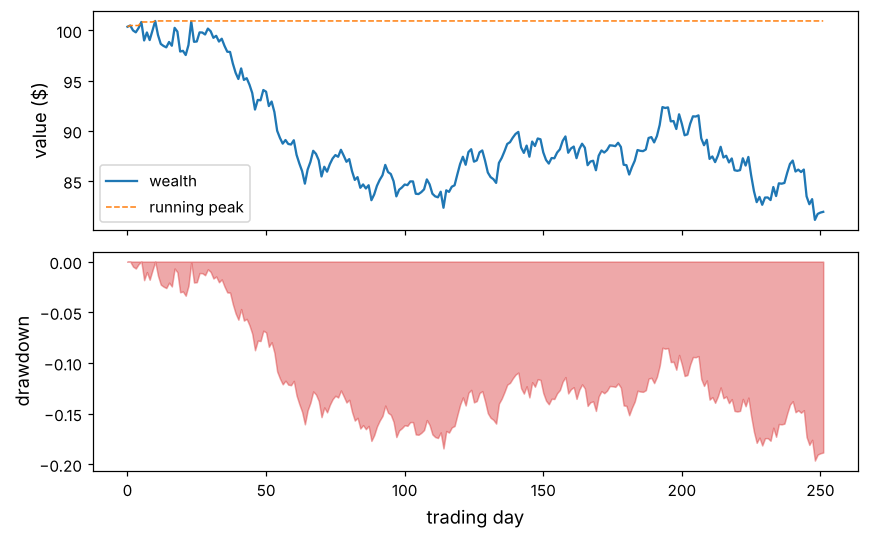

In [17]:
daily = rng.normal(0.0004, 0.01, 252)          # one year of daily returns
wealth = 100 * np.cumprod(1 + daily)            # value of $100 invested
peak = np.maximum.accumulate(wealth)            # running maximum
drawdown = wealth / peak - 1
print(f"final value {wealth[-1]:.2f}, max drawdown {drawdown.min():.1%}")
R["mdd"] = f"{-drawdown.min():.1%}"

fig, ax = plt.subplots(2, 1, figsize=(8, 5), sharex=True)
ax[0].plot(wealth, label="wealth")
ax[0].plot(peak, "--", lw=1, label="running peak")
ax[0].set_ylabel("value ($)"); ax[0].legend()
ax[1].fill_between(np.arange(252), drawdown, 0, color="tab:red", alpha=0.4)
ax[1].set_ylabel("drawdown"); ax[1].set_xlabel("trading day")
save_fig("wealth_drawdown")
plt.show()

![Figure 1-1. A simulated year: wealth, its running peak, and the drawdown below the peak, all from three vectorised lines.](images/wealth_drawdown.png)

`np.maximum.accumulate` is a ufunc method: every ufunc has `.accumulate` (running result) and `.reduce` (final result). The worst drawdown here is 19.6%. Drawdown is how far you are below your best value so far; Chapter 2 of the Financial ML course uses exactly these three lines to score strategies.

## Broadcasting: how arrays of different shapes combine

What happens if you subtract a vector of three column means from a $5 \times 3$ table? NumPy **broadcasts**: it virtually stretches the smaller array so the shapes match, without copying any data.

:::math
Two shapes are compatible if, comparing them **from the right**, each pair of dimensions is equal or one of them is 1. Missing dimensions on the left count as 1. The result takes the larger size in each position. For example `(5, 3)` and `(3,)`: right-align to `(5, 3)` and `(1, 3)`, the 1 stretches to 5, the result is `(5, 3)`. But `(5, 3)` and `(5,)` → `(5, 3)` and `(1, 5)`: 3 ≠ 5, error.
:::

In [18]:
col_mean = X.mean(axis=0)            # shape (3,)
demeaned = X - col_mean              # (5,3) - (3,) -> (5,3): each column centred
print(demeaned.mean(axis=0).round(12))

row_mean = X.mean(axis=1)            # shape (5,)
try:
    X - row_mean                     # (5,3) - (5,) -> error
except ValueError as e:
    print("error:", e)
centred_rows = X - row_mean[:, np.newaxis]   # (5,3) - (5,1) -> works
print(centred_rows.mean(axis=1).round(12))

[0. 0. 0.]
error: operands could not be broadcast together with shapes (5,3) (5,) 
[0. 0. 0. 0. 0.]


The fix `row_mean[:, np.newaxis]` (or `row_mean.reshape(-1, 1)`, or `keepdims=True`) turns the shape `(5,)` into `(5, 1)`, a column, which can stretch across the 3 columns. Try both cases in the **Broadcasting** tab of the playground.

Broadcasting makes many “double loop” computations one line:

In [19]:
# z-scores: standardise every asset's returns
Z = (X - X.mean(axis=0)) / X.std(axis=0, ddof=1)
print(Z.std(axis=0, ddof=1))

# outer product: payoff of a call for many prices and many strikes at once
S = np.linspace(80, 120, 5)[:, None]      # shape (5, 1)
K = np.array([90, 100, 110])[None, :]     # shape (1, 3)
payoff = np.maximum(S - K, 0)              # shape (5, 3)
print(payoff)

[1. 1. 1.]
[[ 0.  0.  0.]
 [ 0.  0.  0.]
 [10.  0.  0.]
 [20. 10.  0.]
 [30. 20. 10.]]


:::trap
Broadcasting never complains when the shapes are compatible but your *meaning* is wrong. Subtracting a `(3,)` vector of asset means from a `(3, 3)` covariance matrix runs fine and is nonsense. Print shapes while you develop: `print(a.shape, b.shape)` is the cheapest debugging tool in quant work.
:::

## Reshaping, combining, sorting

In [20]:
a = np.arange(12)
print(a.reshape(3, 4))
print(a.reshape(2, -1).shape)        # -1: "work this dimension out for me"
M = a.reshape(3, 4)
print(M.T.shape, M.ravel()[:5])      # transpose; flatten (a view when possible)
print(np.vstack([M[0], M[1]]))       # stack rows
print(np.hstack([M[:, :1], M[:, -1:]]))
print(np.concatenate([M, M], axis=0).shape, np.stack([M, M]).shape)   # join vs new axis

[[ 0  1  2  3]
 [ 4  5  6  7]
 [ 8  9 10 11]]
(2, 6)
(4, 3) [0 1 2 3 4]
[[0 1 2 3]
 [4 5 6 7]]
[[ 0  3]
 [ 4  7]
 [ 8 11]]
(6, 4) (2, 3, 4)


Sorting and ranking are central in quant work: cross-sectional strategies buy the best-ranked assets.

In [21]:
mom = np.array([0.12, -0.05, 0.30, 0.07, -0.20])     # 12-month returns of 5 stocks
order = np.argsort(mom)              # positions that would sort it, ascending
print("order:", order, "sorted:", mom[order])
ranks = np.empty_like(order); ranks[order] = np.arange(len(mom))
print("rank of each stock (0 = worst):", ranks)
print("top 2 stocks:", np.argsort(mom)[-2:][::-1])
print("median, 90th percentile:", np.median(mom), np.percentile(mom, 90))
print("where would 0.10 go in the sorted list?", np.searchsorted(np.sort(mom), 0.10))
vals, counts = np.unique(np.sign(mom), return_counts=True)
print(dict(zip(vals, counts)))

order: [4 1 3 0 2] sorted: [-0.2  -0.05  0.07  0.12  0.3 ]
rank of each stock (0 = worst): [3 1 4 2 0]
top 2 stocks: [2 0]
median, 90th percentile: 0.07 0.228
where would 0.10 go in the sorted list? 3
{np.float64(-1.0): np.int64(2), np.float64(1.0): np.int64(3)}


## Linear algebra for portfolios

A portfolio is a vector of weights $w$ and the asset returns on one day are a vector $r$. The portfolio return is the dot product $w^\top r = \sum_i w_i r_i$. Over many days stored as a matrix $X$ (days × assets), the portfolio's daily returns are the matrix-vector product $X w$. In NumPy, `@` is matrix multiplication.

In [22]:
n_days, n_assets = 1000, 4
true_cov = np.array([[0.040, 0.012, 0.010, 0.002],
                     [0.012, 0.030, 0.008, 0.001],
                     [0.010, 0.008, 0.050, 0.003],
                     [0.002, 0.001, 0.003, 0.010]]) / 252      # daily covariance
L = np.linalg.cholesky(true_cov)                # true_cov = L @ L.T
rets = rng.standard_normal((n_days, n_assets)) @ L.T + 0.0003
w = np.array([0.4, 0.3, 0.2, 0.1])

port = rets @ w                                 # (1000,4) @ (4,) -> (1000,)
Sigma = np.cov(rets, rowvar=False)              # 4x4 sample covariance (ddof=1)
print("portfolio vol from the data:", port.std(ddof=1) * np.sqrt(252))
print("portfolio vol from w'Σw:   ", np.sqrt(w @ Sigma @ w * 252))

portfolio vol from the data: 0.13021260779571328
portfolio vol from w'Σw:    0.1302126077957133


Two things happened. First, the **Cholesky factor** $L$ turned independent standard normal draws into correlated ones: if $z$ has identity covariance then $Lz$ has covariance $LL^\top = \Sigma$. This is how every Monte Carlo risk system simulates correlated assets. Second, the portfolio variance is the **quadratic form** $\sigma_p^2 = w^\top \Sigma w$, and it matches the variance of the simulated portfolio returns exactly (it is an identity for the sample covariance).

### Solving equations: the minimum-variance portfolio

The fully invested portfolio with the smallest variance solves $\min_w w^\top \Sigma w$ subject to $\mathbf{1}^\top w = 1$. With a Lagrange multiplier the answer is $w^* = \Sigma^{-1}\mathbf{1} / (\mathbf{1}^\top \Sigma^{-1} \mathbf{1})$. Never compute $\Sigma^{-1}$ explicitly: solve the linear system $\Sigma x = \mathbf{1}$, which is faster and more accurate.

In [23]:
ones = np.ones(n_assets)
x = np.linalg.solve(Sigma, ones)        # Σ x = 1
w_mv = x / x.sum()
print("minimum-variance weights:", w_mv.round(3))
print("its vol:", np.sqrt(w_mv @ Sigma @ w_mv * 252).round(4), " vs our portfolio:", np.sqrt(w @ Sigma @ w * 252).round(4))
R["w_mv_last"] = f"{w_mv[-1]:.0%}"

minimum-variance weights: [0.071 0.187 0.058 0.683]
its vol: 0.0863  vs our portfolio: 0.1302


Most of the weight (68%) goes to the fourth asset, the quietest one with low correlations. Chapter 4 of the Financial ML course shows why this tidy maths behaves badly with real, noisy estimates of $\Sigma$, and how to fix it.

### Regression with least squares: a stock's beta

The beta of a stock against the market is the slope in $r_{\text{stock}} = \alpha + \beta\, r_{\text{mkt}} + \varepsilon$ (Finance From Zero, Lesson 10). `np.linalg.lstsq` solves any linear least-squares problem $\min_b \lVert y - Ab \rVert^2$.

In [24]:
mkt = rets[:, 0]
stock = 0.0001 + 1.3 * mkt + rng.normal(0, 0.008, n_days)
A = np.column_stack([np.ones(n_days), mkt])     # design matrix: [1, r_mkt]
(alpha, beta), *_ = np.linalg.lstsq(A, stock, rcond=None)
print(f"alpha {alpha:.5f}  beta {beta:.3f}")
print("same beta from the covariance formula:", np.cov(stock, mkt)[0, 1] / mkt.var(ddof=1))

alpha 0.00006  beta 1.298
same beta from the covariance formula: 1.298424309233844


### Eigenvalues: what moves the market (PCA)

The eigenvectors of a covariance matrix are uncorrelated “portfolios” (principal components), and each eigenvalue is the variance of its component. In stock markets the first component is almost always “everything moves together”: the market factor.

In [25]:
vals, vecs = np.linalg.eigh(Sigma)            # eigh: for symmetric matrices, ascending
vals, vecs = vals[::-1], vecs[:, ::-1]
print("share of variance per component:", (vals / vals.sum()).round(3))
print("first component weights:", vecs[:, 0].round(2))

share of variance per component: [0.485 0.281 0.159 0.075]
first component weights: [-0.54 -0.38 -0.75 -0.08]


:::quant
`eigh` (not `eig`) is the right function for covariance matrices: it uses the symmetry, returns real numbers and sorts eigenvalues in ascending order. `np.linalg.svd` gives the same components directly from the (demeaned) data matrix and is numerically the safest way to do PCA. Chapter 4 uses PCA to clean covariance matrices and Chapter 6 to build statistical factors.
:::

## Random numbers and Monte Carlo

Use the modern **Generator** API, `rng = np.random.default_rng(seed)`, not the legacy `np.random.seed` and `np.random.normal`. A Generator is an object you pass around, so different parts of a program do not interfere, and results are reproducible.

In [26]:
rng2 = np.random.default_rng(7)
print(rng2.normal(0, 1, 3))                  # mean 0, sd 1
print(rng2.uniform(0, 1, 3))
print(rng2.integers(1, 7, 10))               # dice: 1..6
print(rng2.choice(["up", "down"], 5, p=[0.55, 0.45]))
print(rng2.permutation(5))

[ 0.00123015  0.29874554 -0.27413786]
[0.22520719 0.30016628 0.87355345]
[6 1 3 5 1 5 1 3 5 2]
['up' 'up' 'up' 'up' 'down']
[1 4 2 0 3]


### Simulating 10,000 price paths at once

Geometric Brownian motion (Finance From Zero, Lesson 8) says the log price takes Gaussian steps: $\ln S_{t+\Delta t} = \ln S_t + (\mu - \tfrac12\sigma^2)\Delta t + \sigma\sqrt{\Delta t}\, Z$. With broadcasting we simulate all paths and all days in one array of shape `(paths, days)`.

2,520,000 random steps in 184 ms


mean final price: 107.64  theory: 107.25
5% and 95% quantiles: [ 75.9 147.3]


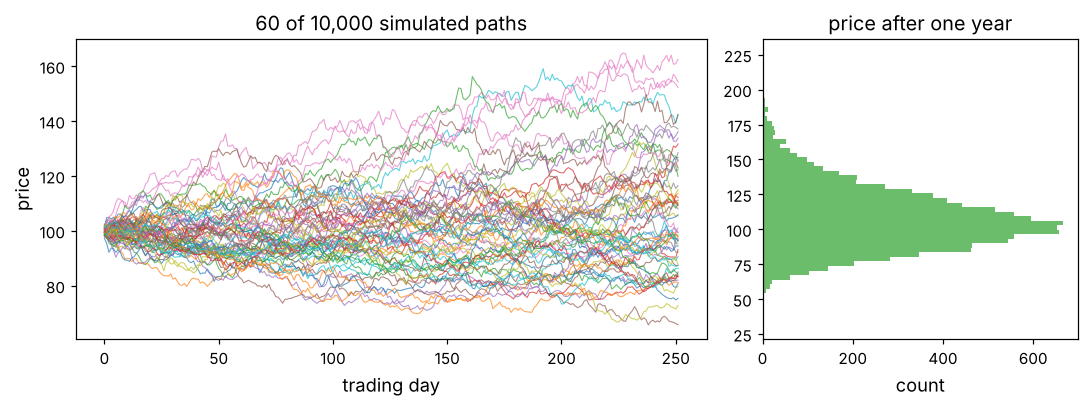

In [27]:
S0, mu, sigma, T, n_steps, n_paths = 100.0, 0.07, 0.20, 1.0, 252, 10_000
dt = T / n_steps
t0 = time.perf_counter()
Z = rng.standard_normal((n_paths, n_steps))
log_paths = np.log(S0) + np.cumsum((mu - 0.5 * sigma**2) * dt + sigma * np.sqrt(dt) * Z, axis=1)
paths = np.exp(log_paths)
elapsed = time.perf_counter() - t0
print(f"{n_paths * n_steps:,} random steps in {elapsed*1000:.0f} ms")
R["mc_ms"] = f"{elapsed*1000:.0f}"

ST = paths[:, -1]
print("mean final price:", ST.mean().round(2), " theory:", round(S0 * np.exp(mu * T), 2))
print("5% and 95% quantiles:", np.percentile(ST, [5, 95]).round(1))

fig, ax = plt.subplots(1, 2, figsize=(10, 3.8), gridspec_kw={"width_ratios": [2, 1]})
ax[0].plot(paths[:60].T, lw=0.7, alpha=0.7)
ax[0].set_xlabel("trading day"); ax[0].set_ylabel("price")
ax[0].set_title("60 of 10,000 simulated paths")
ax[1].hist(ST, bins=60, orientation="horizontal", color="tab:green", alpha=0.7)
ax[1].set_xlabel("count"); ax[1].set_title("price after one year")
save_fig("gbm_paths")
plt.show()

![Figure 1-2. Monte Carlo with broadcasting: 2.5 million random steps in one array. The final prices are lognormal, skewed to the right.](images/gbm_paths.png)

That took about 184 ms. The same simulation with nested Python loops takes tens of seconds. With the paths in hand, the price of any option is a one-liner: discount the average payoff under the risk-neutral drift.

In [28]:
r_f, K = 0.03, 105.0
Z = rng.standard_normal(200_000)
ST_q = S0 * np.exp((r_f - 0.5 * sigma**2) * T + sigma * np.sqrt(T) * Z)   # risk-neutral
mc_price = np.exp(-r_f * T) * np.maximum(ST_q - K, 0).mean()
se = np.exp(-r_f * T) * np.maximum(ST_q - K, 0).std(ddof=1) / np.sqrt(len(Z))

from math import erf, log, sqrt, exp
N = lambda x: 0.5 * (1 + erf(x / sqrt(2)))
d1 = (log(S0 / K) + (r_f + 0.5 * sigma**2) * T) / (sigma * sqrt(T)); d2 = d1 - sigma * sqrt(T)
bs = S0 * N(d1) - K * exp(-r_f * T) * N(d2)
print(f"Monte Carlo {mc_price:.3f} ± {1.96*se:.3f}   Black–Scholes {bs:.3f}")
R["mc_price"], R["bs_price"] = f"{mc_price:.2f}", f"{bs:.2f}"

Monte Carlo 7.136 ± 0.055   Black–Scholes 7.128


The Monte Carlo price 7.14 agrees with the Black–Scholes formula (7.13) within its 95% error band. The error shrinks like $1/\sqrt{n}$, so four times the paths halves it.

### The bootstrap: uncertainty without formulas

Resampling the data with replacement many times shows how much a statistic would vary from sample to sample. Here: how uncertain is a Sharpe ratio estimated from one year of returns?

In [29]:
def sharpe(x, axis=-1):
    return x.mean(axis=axis) / x.std(axis=axis, ddof=1) * np.sqrt(252)

idx = rng.integers(0, len(daily), size=(5000, len(daily)))    # 5000 resamples at once
boot = sharpe(daily[idx], axis=1)
lo, hi = np.percentile(boot, [2.5, 97.5])
print(f"Sharpe {sharpe(daily):.2f}, 95% bootstrap interval [{lo:.2f}, {hi:.2f}]")
R["sh_lo"], R["sh_hi"] = f"{lo:.2f}", f"{hi:.2f}"

Sharpe -1.20, 95% bootstrap interval [-3.16, 0.82]


One year of data gives an interval from -3.16 to 0.82: you cannot tell a good strategy from a bad one with a single year. Keep this result in mind; the whole Financial ML course is built around it.

:::trap
The simple bootstrap assumes the returns are independent. Real returns have volatility clustering (calm and wild periods), so quants resample *blocks* of consecutive days instead. Chapter 1 of the Financial ML course builds the block bootstrap.
:::

## Performance tricks quants use

### Rolling windows without loops

A 20-day rolling volatility needs, for every day, the standard deviation of the last 20 returns. `sliding_window_view` creates all windows as a view (no copying) with shape `(n - 19, 20)`, and one vectorised `std` finishes the job.

In [30]:
from numpy.lib.stride_tricks import sliding_window_view

r = rng.normal(0, 0.01, 2000)
t0 = time.perf_counter()
loop_vol = np.array([r[i - 20:i].std(ddof=1) for i in range(20, len(r) + 1)])
t_loop = time.perf_counter() - t0
t0 = time.perf_counter()
win = sliding_window_view(r, 20)          # shape (1981, 20), a view
fast_vol = win.std(axis=1, ddof=1)
t_fast = time.perf_counter() - t0
print(win.shape, np.allclose(loop_vol, fast_vol), f"{t_loop/t_fast:.0f}x faster")

(1981, 20) True 45x faster


pandas' `.rolling()` (Toolkit Chapter 2) does this for you with dates attached; under the hood it is the same idea.

### `einsum`: index notation for arrays

`np.einsum` lets you write a computation in Einstein index notation. It is perfect for batched linear algebra, such as the variance of many portfolios at once, $\sigma_k^2 = \sum_{i,j} w_{ki} \Sigma_{ij} w_{kj}$:

In [31]:
W = rng.dirichlet(np.ones(n_assets), size=5000)          # 5000 random portfolios
var_einsum = np.einsum("ki,ij,kj->k", W, Sigma, W)
var_loop = np.array([wk @ Sigma @ wk for wk in W])
print(np.allclose(var_einsum, var_loop), var_einsum.shape)

True (5000,)


### In-place operations and memory

`a += 1` and `np.multiply(a, 2, out=a)` modify an array without allocating a new one, which matters when arrays have hundreds of millions of elements. `float32` halves memory and is the default in deep learning, but its 7 digits are not enough for summing long return series; keep `float64` for finance calculations.

In [32]:
big = np.ones(10_000_000)
print(f"{big.nbytes / 1e6:.0f} MB as float64, {big.astype(np.float32).nbytes / 1e6:.0f} MB as float32")
big *= 1.01                     # in place: no new 80 MB array
print(big[:3])

80 MB as float64, 40 MB as float32
[1.01 1.01 1.01]


## Saving and loading

In [33]:
np.save("returns.npy", rets)                          # one array, fast binary
np.savez_compressed("bundle.npz", rets=rets, w=w)     # several arrays
back = np.load("bundle.npz")
print(back["rets"].shape, back["w"])
np.savetxt("weights.csv", w, delimiter=",", fmt="%.4f")
print(np.loadtxt("weights.csv", delimiter=","))
import os
for f in ["returns.npy", "bundle.npz", "weights.csv"]:
    os.remove(f)

(1000, 4) [0.4 0.3 0.2 0.1]
[0.4 0.3 0.2 0.1]


For tables with dates and column names, use pandas and Parquet or CSV instead (Toolkit Chapter 2).

## The mistakes that cost quants money

| Mistake | What happens | Fix |
|---|---|---|
| Modifying a slice | The original data changes silently | `.copy()` when you intend to modify |
| `np.std` vs pandas `.std()` | Volatility differs by $\sqrt{n/(n-1)}$ | Always write `ddof=1` |
| Wrong `axis` | Averages over assets instead of days | Write the shape down; the axis you name disappears |
| Silent broadcasting | Shapes fit but the meaning is wrong | Print shapes; use `[:, None]` deliberately |
| `==` on floats | `0.1 + 0.2 != 0.3` | `np.isclose`, `np.allclose` |
| `nan` in data | Every sum becomes `nan` | `np.isnan`, `np.nanmean`, or clean first (pandas) |
| Integer overflow | Large products wrap around | `float64`, or check ranges |
| `np.linalg.inv` | Slow and inaccurate | `np.linalg.solve` |
| Legacy `np.random.seed` | Hidden global state | `rng = np.random.default_rng(seed)` |

## Exercises

:::exercise
1. Create the array of the first 20 square numbers without a loop, then keep only the even ones.
2. Given a `(250, 5)` array of daily returns, compute each asset's annualised mean return and volatility (`ddof=1`), and the index of the asset with the highest ratio of the two.
3. Write a function `max_drawdown(prices)` in three lines that works on a 1-D array, then make it work on a 2-D array of shape `(days, assets)` returning one number per asset.
4. Without a loop, compute the 50-day moving average of a price series with `np.convolve` and with `sliding_window_view`, and check that they agree.
5. Simulate 10,000 two-asset return paths with correlation 0.6 using a Cholesky factor, and verify the sample correlation.
6. Estimate the probability that a GBM stock ($\mu = 7\%$, $\sigma = 20\%$) ends one year below 80 by Monte Carlo, and compare with the exact lognormal answer.
:::

<details><summary>Solutions</summary>

In [34]:
# 1
sq = np.arange(1, 21) ** 2
print(sq[sq % 2 == 0])

# 2
Xr = rng.normal(0.0004, 0.01, (250, 5))
mu_a = Xr.mean(axis=0) * 252
vol_a = Xr.std(axis=0, ddof=1) * np.sqrt(252)
print(mu_a.round(3), vol_a.round(3), np.argmax(mu_a / vol_a))

# 3
def max_drawdown(prices):
    prices = np.asarray(prices)
    return (prices / np.maximum.accumulate(prices, axis=0) - 1).min(axis=0)
Pp = 100 * np.cumprod(1 + Xr, axis=0)
print(max_drawdown(Pp[:, 0]), max_drawdown(Pp))

# 4
px = Pp[:, 0]
ma1 = np.convolve(px, np.ones(50) / 50, mode="valid")
ma2 = sliding_window_view(px, 50).mean(axis=1)
print(np.allclose(ma1, ma2), ma1.shape)

# 5
C = np.array([[1, 0.6], [0.6, 1]])
Zc = rng.standard_normal((10_000, 2)) @ np.linalg.cholesky(C).T
print(np.corrcoef(Zc, rowvar=False)[0, 1].round(3))

# 6
Zg = rng.standard_normal(1_000_000)
ST6 = 100 * np.exp((0.07 - 0.02) + 0.20 * Zg)
from math import log
exact = N((log(80 / 100) - (0.07 - 0.02)) / 0.20)
print(f"MC {np.mean(ST6 < 80):.4f}  exact {exact:.4f}")

[  4  16  36  64 100 144 196 256 324 400]
[-0.089  0.376 -0.01   0.568 -0.013] [0.151 0.167 0.145 0.167 0.164] 3
-0.1319321214985646 [-0.13193212 -0.1305327  -0.13107879 -0.0660506  -0.15040882]
True (201,)
0.608
MC 0.0861  exact 0.0860


</details>

## What's next

You can now think in arrays. Toolkit Chapter 2 puts names and dates on them: pandas turns a NumPy array into a table with a time index, which is how market data is actually stored and analysed.